# Stacking with TabPFN-3

This notebook builds upon the stacking notebook from Chris: https://www.kaggle.com/code/cdeotte/gpu-logistic-regression-stacker

It replaces the stacking model with TabPFN-3 and also incorporates the additional features.

### What is TabPFN?

TabPFN (Tabular Prior-data Fitted Network) is a transformer pre-trained on millions of synthetic tabular datasets. Rather than training from scratch on your data, it performs *in-context learning*: your training rows go in as context and predictions come straight out. The recent TabPFN-3 model scales to one million rows, which is what allows us to directly tackle the dataset at hand.

| | |
|---|---|
| **Docs** | https://docs.priorlabs.ai |
| **GitHub** | https://github.com/PriorLabs/TabPFN |
| **TabPFN-3: Technical Report** | https://arxiv.org/abs/2605.13986 |
| **Hugging Face** | https://huggingface.co/Prior-Labs/tabpfn_3 |
| **Meet TabPFN-3** | https://priorlabs.ai/tabpfn |
| **Prior Labs** | https://priorlabs.ai |
| **Install** | `pip install tabpfn` |

In [1]:
!uv pip install tabpfn --system -q

In [2]:
import os
os.environ["TABPFN_MODEL_CACHE_DIR"] = "/kaggle/input/models/prior-labsai/tabpfn-3/pytorch/default/1"

In [3]:
import numpy as np
import pandas as pd
import warnings
import gc
import time
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import StandardScaler
from pathlib import Path

warnings.filterwarnings('ignore')

N_FOLDS     = 5
N_SEEDS     = 5
SEEDS       = list(range(42, 42 + N_SEEDS))
EPS         = 1e-15
LOGIT_CLIP  = 30.0
epochs      = 1000
C           = 1e-1
n_classes   = 3

ID = 'id'
TARGET      = 'class'
target_map  = {'GALAXY': 0, 'QSO': 1, 'STAR': 2}
inv_map     = {v: k for k, v in target_map.items()}
BOOST       = 1.0

VER         = 1

def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
print(f'Seeds: {SEEDS}')

class PyTorchMultiLogReg(nn.Module):
    def __init__(self, in_features, out_features=3):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features)

    def forward(self, x):
        return self.linear(x)

# Format: ('MODEL_NAME', 'oof_file.npy', 'test_file.npy')
# Update paths here if your model outputs live in another folder.
OOF_DIR = '/kaggle/input/datasets/fachri00/ps6e6-stacker/oof'
TEST_PRED_DIR = '/kaggle/input/datasets/fachri00/ps6e6-stacker/test_pred'
STACKING_FILES = [
    ### Version 2 ###
    ('xgb-0', '/kaggle/input/notebooks/cdeotte/xgb-v0-for-s6e6/oof_xgb_cv.csv', '/kaggle/input/notebooks/cdeotte/xgb-v0-for-s6e6/test_xgb_preds.csv'),
    ('xgb-1', '/kaggle/input/notebooks/cdeotte/xgb-v1-for-s6e6/oof_preds.npy', '/kaggle/input/notebooks/cdeotte/xgb-v1-for-s6e6/test_preds.npy'),
    ('realmlp-0', '/kaggle/input/notebooks/yekenot/ps-s6-e6-realmlp-pytorch/oof_preds.csv', '/kaggle/input/notebooks/yekenot/ps-s6-e6-realmlp-pytorch/test_preds.csv'),
    ('realmlp-1', '/kaggle/input/notebooks/cdeotte/realmlp-v1-for-s6e6/oof_preds.npy', '/kaggle/input/notebooks/cdeotte/realmlp-v1-for-s6e6/test_preds.npy'),
    ('tabm-0', '/kaggle/input/notebooks/donmarch14/s6e6-tabm/oof_preds.csv', '/kaggle/input/notebooks/donmarch14/s6e6-tabm/test_preds.csv'),
    ('cat-0', '/kaggle/input/notebooks/cdeotte/cat-v0-for-s6e6/catboost_oof_predictions.csv', '/kaggle/input/notebooks/cdeotte/cat-v0-for-s6e6/catboost_test_predictions.csv'),
    ### Version 3 ###
    ('realmlp-2', '/kaggle/input/notebooks/nawfeelrahman1124444/single-realmlp-0-96980-v10/train_oof/realmlp-5_oof.csv', '/kaggle/input/notebooks/nawfeelrahman1124444/single-realmlp-0-96980-v10/test_preds/realmlp-5_test_preds.csv'),
    ('tabicl-2', '/kaggle/input/notebooks/cdeotte/tabicl-v2-for-s6e6/train_oof/tabicl-2_oof.npy', '/kaggle/input/notebooks/cdeotte/tabicl-v2-for-s6e6/test_preds/tabicl-2_test_preds.npy'),
    ('lgbm-3', '/kaggle/input/notebooks/cdeotte/lgbm-v3-for-s6e6/train_oof/lgbm-3_oof.npy', '/kaggle/input/notebooks/cdeotte/lgbm-v3-for-s6e6/test_preds/lgbm-3_test_preds.npy'),
    ('logreg-1', '/kaggle/input/notebooks/cdeotte/logreg-v1-for-s6e6/train_oof/logreg-1_oof.npy', '/kaggle/input/notebooks/cdeotte/logreg-v1-for-s6e6/test_preds/logreg-1_test_preds.npy'),
    ('nn-1', '/kaggle/input/notebooks/cdeotte/nn-v1-for-s6e6/train_oof/nn-1_oof.npy', '/kaggle/input/notebooks/cdeotte/nn-v1-for-s6e6/test_preds/nn-1_test_preds.npy'),
    ('xgb-3', '/kaggle/input/notebooks/cdeotte/xgb-v3-for-s6e6/stellar_class_xgb_oof_preds_raw.npy', '/kaggle/input/notebooks/cdeotte/xgb-v3-for-s6e6/stellar_class_xgb_test_preds_raw.npy'),
    ### Version 4 ###
    ('xgb-5', '/kaggle/input/notebooks/cdeotte/xgb-v5-for-s6e6/train_oof/xgb-5_oof.npy', '/kaggle/input/notebooks/cdeotte/xgb-v5-for-s6e6/test_preds/xgb-5_test_preds.npy'),
    ### Version 6 ###
    ('realmlp-5', '/kaggle/input/notebooks/cdeotte/realmlp-v5-for-s6e6/train_oof/realmlp-5_oof.npy', '/kaggle/input/notebooks/cdeotte/realmlp-v5-for-s6e6/test_preds/realmlp-5_test_preds.npy'),
    ('nn-2', '/kaggle/input/notebooks/cdeotte/nn-v2-for-s6e6/train_oof/nn-2_oof.npy', '/kaggle/input/notebooks/cdeotte/nn-v2-for-s6e6/test_preds/nn-2_test_preds.npy'),
    ### Version 7 ###
    ('cat-3', '/kaggle/input/notebooks/cdeotte/cat-v3-for-s6e6/train_oof/cat-3_oof.npy', '/kaggle/input/notebooks/cdeotte/cat-v3-for-s6e6/test_preds/cat-3_test_preds.npy'),
    ### Version 8 ###
    ('lgbm-5', '/kaggle/input/notebooks/omidbaghchehsaraei/lightgbm-stellar-class-cv-0-96816-lb-0-96885/oof_preds.csv', '/kaggle/input/notebooks/omidbaghchehsaraei/lightgbm-stellar-class-cv-0-96816-lb-0-96885/test_preds.csv'),
    ('xgb-6', '/kaggle/input/notebooks/kirill0212/ps6e6-one-vs-rest-xgb/oof_final.csv', '/kaggle/input/notebooks/kirill0212/ps6e6-one-vs-rest-xgb/test_final.csv'),
    ('tabm-1', '/kaggle/input/notebooks/kirill0212/ps6e6-one-vs-rest-tabm/oof_final.csv', '/kaggle/input/notebooks/kirill0212/ps6e6-one-vs-rest-tabm/test_final.csv'),
    # New
    ('nn-3', '/kaggle/input/notebooks/omidbaghchehsaraei/sklearn-mlp-stellar-class-cv-0-96506-lb-0-96797/oof_preds.csv', '/kaggle/input/notebooks/omidbaghchehsaraei/sklearn-mlp-stellar-class-cv-0-96506-lb-0-96797/test_preds.csv'),
    ('fl-1', '/kaggle/input/notebooks/omidbaghchehsaraei/flaml-xgb-cv-0-96832-lb-0-96943-stellar-class/oof_preds.csv', '/kaggle/input/notebooks/omidbaghchehsaraei/flaml-xgb-cv-0-96832-lb-0-96943-stellar-class/test_preds.csv'),
    ('tabpfn-1', '/kaggle/input/notebooks/omidbaghchehsaraei/tabpfn-predicting-stellar-class-galaxy-star-qso/oof_preds.csv', '/kaggle/input/notebooks/omidbaghchehsaraei/tabpfn-predicting-stellar-class-galaxy-star-qso/test_preds.csv'),
    ('rf-1', '/kaggle/input/notebooks/omidbaghchehsaraei/stellar-classification-via-rf-galaxy-star-qso/oof_preds.csv', '/kaggle/input/notebooks/omidbaghchehsaraei/stellar-classification-via-rf-galaxy-star-qso/test_preds.csv'),
    ('tabtrans-1', '/kaggle/input/notebooks/omidbaghchehsaraei/predicting-galaxy-star-qso-with-tabtransformer/oof_preds.csv', '/kaggle/input/notebooks/omidbaghchehsaraei/predicting-galaxy-star-qso-with-tabtransformer/test_preds.csv'),
    ('lgbm-6', '/kaggle/input/notebooks/stephentarter/ps-s06e06-lightgbm/predictions/lgb_oof_probs.csv', '/kaggle/input/notebooks/stephentarter/ps-s06e06-lightgbm/predictions/lgb_test_probs.csv'),
    ('xgb-8', '/kaggle/input/notebooks/stephentarter/ps-s06e06-xgboost/predictions/xgb_oof_probs.csv', '/kaggle/input/notebooks/stephentarter/ps-s06e06-xgboost/predictions/xgb_test_probs.csv'),
    ('danet-1', '/kaggle/input/notebooks/omidbaghchehsaraei/danets-galaxy-star-qso-classification/oof_preds.csv', '/kaggle/input/notebooks/omidbaghchehsaraei/danets-galaxy-star-qso-classification/test_preds.csv'),
    ('convnet-1', '/kaggle/input/notebooks/omidbaghchehsaraei/convolutional-neural-network-astronomical-objects/oof_preds.csv', '/kaggle/input/notebooks/omidbaghchehsaraei/convolutional-neural-network-astronomical-objects/test_preds.csv'),
    ('trompt-1', '/kaggle/input/notebooks/omidbaghchehsaraei/trompt-predicting-stellar-class-galaxy-star-qso/oof_preds.csv', '/kaggle/input/notebooks/omidbaghchehsaraei/trompt-predicting-stellar-class-galaxy-star-qso/test_preds.csv'),
    ('cat-4', '/kaggle/input/notebooks/stephentarter/ps-s06e06-catboost/predictions/catboost_oof_probs.csv', '/kaggle/input/notebooks/stephentarter/ps-s06e06-catboost/predictions/catboost_test_probs.csv'),
    ('realmlp-6', '/kaggle/input/notebooks/kirill0212/ps-s6-e6-realmlp-pytorch-f80811/oof_preds.csv', '/kaggle/input/notebooks/kirill0212/ps-s6-e6-realmlp-pytorch-f80811/test_preds.csv'),
    ('fttrans-1', '/kaggle/input/notebooks/omidbaghchehsaraei/classifying-galaxy-star-qso-ft-transformer/oof_preds.csv', '/kaggle/input/notebooks/omidbaghchehsaraei/classifying-galaxy-star-qso-ft-transformer/test_preds.csv'),
]

print(f'Total models: {len(STACKING_FILES)}')


Using device: cuda
Seeds: [42, 43, 44, 45, 46]
Total models: 32


In [4]:
train = pd.read_csv('/kaggle/input/competitions/playground-series-s6e6/train.csv', index_col='id')
test  = pd.read_csv('/kaggle/input/competitions/playground-series-s6e6/test.csv',  index_col='id')

train_id = train.reset_index()['id']
test_id = test.reset_index()['id']

y = train[TARGET].map(target_map).astype(int).values
N = len(y)
M = len(test)
print(f'Train: {N:,} | Test: {M:,}')
print(f'Class dist: {dict(zip(*np.unique(y, return_counts=True)))}')

def prob_to_logit(p):
    p = np.clip(p, EPS, 1.0 - EPS).astype(np.float64)
    return np.clip(np.log(p / (1.0 - p)), -LOGIT_CLIP, LOGIT_CLIP).astype(np.float32)

def load_preds(path, expected_rows=None):
    if path.lower().endswith(".csv"):
        df = pd.read_csv(path)

        # Case 1: broken flattened CSV with one column of length expected_rows * 3
        if df.shape[1] == 1:
            vals = df.iloc[:, 0].values

            if expected_rows is not None:
                assert len(vals) == expected_rows * 3, (
                    f'{path}: one-column CSV has length {len(vals)}, '
                    f'expected {expected_rows * 3}'
                )

            assert len(vals) % 3 == 0, (
                f'{path}: one-column CSV length {len(vals)} is not divisible by 3'
            )

            return vals.reshape(-1, 3)

        # Case 2: normal CSV; use last 3 columns as probabilities
        return df.iloc[:, -3:].values[:expected_rows]

    arr = np.load(path)

    if arr.ndim == 3:
        arr = arr.mean(axis=0)

    return arr

loaded_oofs  = []
loaded_tests = []
display_names = []

print('\nLoading models:')
for name, oof_f, test_f in STACKING_FILES:
    try:
        o = load_preds(oof_f, expected_rows=N)
        o = prob_to_logit(o)

        t = load_preds(test_f, expected_rows=M)
        t = prob_to_logit(t)

        assert o.shape == (N, 3), f'OOF shape {o.shape} != {(N, 3)}'
        assert t.shape == (M, 3), f'Test shape {t.shape} != {(M, 3)}'

        loaded_oofs.append(o)
        loaded_tests.append(t)
        display_names.append(name)

        print(f'  {name:20s} OOF={o.shape} TEST={t.shape}')

    except Exception as e:
        print(f'  SKIP {name} ({oof_f}, {test_f}): {e}')

n_models = len(loaded_oofs)
if n_models == 0:
    raise RuntimeError('No stacking files loaded. Update STACKING_FILES paths and rerun.')

print(f'\nModels: {n_models} | LR input features: {n_models * 3}')

X = np.concatenate(loaded_oofs, axis=1).astype(np.float32)

X_test = np.concatenate(loaded_tests, axis=1).astype(np.float32)

Train: 577,347 | Test: 247,435
Class dist: {np.int64(0): np.int64(377480), np.int64(1): np.int64(117143), np.int64(2): np.int64(82724)}

Loading models:
  xgb-0                OOF=(577347, 3) TEST=(247435, 3)
  xgb-1                OOF=(577347, 3) TEST=(247435, 3)
  realmlp-0            OOF=(577347, 3) TEST=(247435, 3)
  realmlp-1            OOF=(577347, 3) TEST=(247435, 3)
  tabm-0               OOF=(577347, 3) TEST=(247435, 3)
  cat-0                OOF=(577347, 3) TEST=(247435, 3)
  realmlp-2            OOF=(577347, 3) TEST=(247435, 3)
  tabicl-2             OOF=(577347, 3) TEST=(247435, 3)
  lgbm-3               OOF=(577347, 3) TEST=(247435, 3)
  logreg-1             OOF=(577347, 3) TEST=(247435, 3)
  nn-1                 OOF=(577347, 3) TEST=(247435, 3)
  xgb-3                OOF=(577347, 3) TEST=(247435, 3)
  xgb-5                OOF=(577347, 3) TEST=(247435, 3)
  realmlp-5            OOF=(577347, 3) TEST=(247435, 3)
  nn-2                 OOF=(577347, 3) TEST=(247435, 3)
  cat-3

Seed 42 fold 1: BAC=0.964972 | 9.6s
Seed 42 fold 2: BAC=0.964424 | 3.9s
Seed 42 fold 3: BAC=0.962802 | 3.8s
Seed 42 fold 4: BAC=0.963484 | 3.9s
Seed 42 fold 5: BAC=0.963399 | 3.9s
Seed 42: OOF BAC=0.963816 | folds=['0.964972', '0.964424', '0.962802', '0.963484', '0.963399']
Seed 43 fold 1: BAC=0.962180 | 4.0s
Seed 43 fold 2: BAC=0.964828 | 4.1s
Seed 43 fold 3: BAC=0.963577 | 4.1s
Seed 43 fold 4: BAC=0.964151 | 4.1s
Seed 43 fold 5: BAC=0.963435 | 4.2s
Seed 43: OOF BAC=0.963634 | folds=['0.962180', '0.964828', '0.963577', '0.964151', '0.963435']
Seed 44 fold 1: BAC=0.964174 | 4.2s
Seed 44 fold 2: BAC=0.963780 | 4.2s
Seed 44 fold 3: BAC=0.962261 | 4.3s
Seed 44 fold 4: BAC=0.963460 | 4.3s
Seed 44 fold 5: BAC=0.963806 | 4.4s
Seed 44: OOF BAC=0.963496 | folds=['0.964174', '0.963780', '0.962261', '0.963460', '0.963806']
Seed 45 fold 1: BAC=0.963315 | 4.4s
Seed 45 fold 2: BAC=0.963888 | 4.4s
Seed 45 fold 3: BAC=0.963415 | 4.5s
Seed 45 fold 4: BAC=0.963945 | 4.6s
Seed 45 fold 5: BAC=0.963102 | 

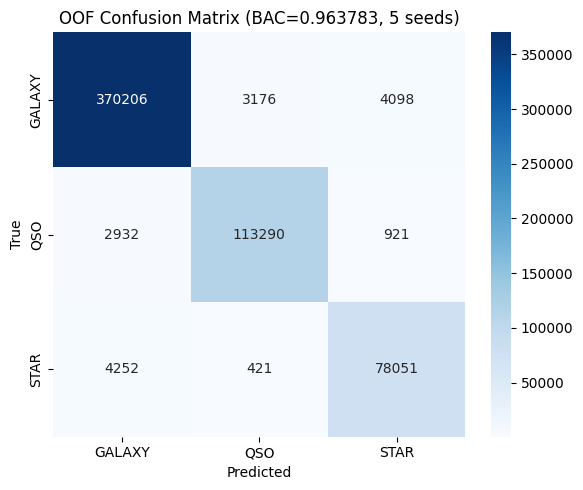

In [5]:
X_test = np.concatenate(loaded_tests, axis=1).astype(np.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32, device=device)
oof_sum    = np.zeros((N, 3), dtype=np.float64)
test_sum   = np.zeros((M, 3), dtype=np.float64)
all_fold_accs = []
X_oof_matrix = np.zeros((N, n_models * 3), dtype=np.float32)

for si, seed in enumerate(SEEDS):
    set_seed(seed)
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    oof_this  = np.zeros((N, 3), dtype=np.float32)
    test_this = np.zeros((M, 3), dtype=np.float32)
    seed_accs = []

    for fold, (tr_idx, val_idx) in enumerate(skf.split(np.zeros(N), y), start=1):
        t0 = time.time()

        meta_tr, meta_va = [], []
        for o in loaded_oofs:
            meta_tr.append(o[tr_idx, :])
            meta_va.append(o[val_idx, :])

        X_tr  = np.concatenate(meta_tr, axis=1).astype(np.float32)
        X_val = np.concatenate(meta_va, axis=1).astype(np.float32)

        if si == len(SEEDS) - 1:
            X_oof_matrix[val_idx, :] = X_val

        y_tr  = y[tr_idx]
        y_val = y[val_idx]

        classes = np.unique(y_tr)
        cw = compute_class_weight('balanced', classes=classes, y=y_tr)
        class_weight = dict(zip(classes, cw))
        class_weight[2] = class_weight[2] * BOOST
        sample_weights = np.array([class_weight[c] for c in y_tr], dtype=np.float32)

        X_tr_t  = torch.tensor(X_tr, dtype=torch.float32, device=device)
        y_tr_t  = torch.tensor(y_tr, dtype=torch.long, device=device)
        sw_t    = torch.tensor(sample_weights, dtype=torch.float32, device=device)
        X_val_t = torch.tensor(X_val, dtype=torch.float32, device=device)

        model = PyTorchMultiLogReg(in_features=X_tr.shape[1], out_features=3).to(device)
        criterion = nn.CrossEntropyLoss(reduction='none')
        weight_decay_mapped = 1.0 / (C * len(y_tr))
        optimizer = optim.Adam([
            {'params': model.linear.weight, 'weight_decay': weight_decay_mapped},
            {'params': model.linear.bias, 'weight_decay': 0.0},
        ], lr=0.01)

        model.train()
        for _ in range(epochs):
            optimizer.zero_grad()
            logits = model(X_tr_t)
            loss = (criterion(logits, y_tr_t)).mean()
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            val_prob = torch.softmax(model(X_val_t), dim=1).cpu().numpy()
            oof_this[val_idx] = val_prob
            test_this += torch.softmax(model(X_test_tensor), dim=1).cpu().numpy() / N_FOLDS

        fold_acc = balanced_accuracy_score(y_val, np.argmax(val_prob, axis=1))
        seed_accs.append(fold_acc)
        print(f'Seed {seed} fold {fold}: BAC={fold_acc:.6f} | {time.time() - t0:.1f}s')

        del model, X_tr_t, y_tr_t, sw_t, X_val_t, X_tr, X_val
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    oof_sum  += oof_this
    test_sum += test_this

    seed_bac = balanced_accuracy_score(y, np.argmax(oof_this, axis=1))
    all_fold_accs.extend(seed_accs)
    print(f'Seed {seed}: OOF BAC={seed_bac:.6f} | folds={[f"{a:.6f}" for a in seed_accs]}')

oof = (oof_sum / N_SEEDS).astype(np.float32)
test_p = (test_sum / N_SEEDS).astype(np.float32)

oof_hard = np.argmax(oof, axis=1)
overall = balanced_accuracy_score(y, oof_hard)
print(f'\nMean fold ACC across all {N_SEEDS * N_FOLDS} folds: {np.mean(all_fold_accs):.6f} +/- {np.std(all_fold_accs):.6f}')
print(f'Overall OOF Balanced ACC ({N_SEEDS}-seed avg): {overall:.6f}')

for k, label in inv_map.items():
    mask = (y == k)
    cls_acc = (oof_hard[mask] == k).mean()
    print(f'  {label:>6s} accuracy: {cls_acc:.6f}  ({(oof_hard[mask] == k).sum()}/{mask.sum()})')

cm = confusion_matrix(y, oof_hard)
print('\nConfusion Matrix (rows=true, cols=pred):')
print(pd.DataFrame(cm, index=[f'True {inv_map[i]}' for i in range(3)], columns=[f'Pred {inv_map[i]}' for i in range(3)]))

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[inv_map[i] for i in range(3)],
            yticklabels=[inv_map[i] for i in range(3)])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'OOF Confusion Matrix (BAC={overall:.6f}, {N_SEEDS} seeds)')
plt.tight_layout()
plt.show()

In [6]:
from tabpfn import TabPFNClassifier
from tqdm import tqdm
SEEDS = [60]
N_SEEDS = len(SEEDS)
oof_preds = np.zeros((len(X), n_classes))
test_preds = np.zeros((len(X_test), n_classes))
all_fold_accs = []

for seed in SEEDS:
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    oof_this  = np.zeros((N, 3), dtype=np.float32)
    test_this = np.zeros((M, 3), dtype=np.float32)
    seed_accs = []

    for fold, (train_idx, val_idx) in tqdm(enumerate(skf.split(X, y))):
        print(f"\n--- Starting Fold {fold + 1} ---")
    
        X_tr, X_val = X[train_idx], X[val_idx]
        y_tr, y_val = y[train_idx], y[val_idx]
    
        model = TabPFNClassifier(
            n_estimators=2,
            balance_probabilities=False,
            random_state=seed,
            device=["cuda:0", "cuda:1"],
        )
    
        model.fit(X_tr, y_tr) 
    
        val_probs = model.predict_proba(X_val)
        test_probs = model.predict_proba(X_test)
    
        oof_this[val_idx] = val_probs
        test_this += test_probs / N_FOLDS
    
        val_preds = np.argmax(val_probs, axis=1)
        score = balanced_accuracy_score(y_val, val_preds)
        seed_accs.append(score)
        print(f"Seed {seed} fold {fold + 1} Balanced Accuracy Score: {score:.6f}")
    
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    oof_preds  += oof_this
    test_preds += test_this

    seed_bac = balanced_accuracy_score(y, np.argmax(oof_this, axis=1))
    all_fold_accs.extend(seed_accs)
    print(f'Seed {seed}: OOF BAC={seed_bac:.6f} | folds={[f"{a:.6f}" for a in seed_accs]}')

oof_preds = (oof_preds / N_SEEDS).astype(np.float32)
test_preds = (test_preds / N_SEEDS).astype(np.float32)

oof_hard = np.argmax(oof_preds, axis=1)
overall = balanced_accuracy_score(y, oof_hard)
print(f'\nMean fold ACC across all {N_SEEDS * N_FOLDS} folds: {np.mean(all_fold_accs):.6f} +/- {np.std(all_fold_accs):.6f}')
print(f'Overall OOF Balanced ACC ({N_SEEDS}-seed avg): {overall:.6f}')

for k, label in inv_map.items():
    mask = (y == k)
    cls_acc = (oof_hard[mask] == k).mean()
    print(f'  {label:>6s} accuracy: {cls_acc:.6f}  ({(oof_hard[mask] == k).sum()}/{mask.sum()})')

cm = confusion_matrix(y, oof_hard)
print('\nConfusion Matrix (rows=true, cols=pred):')
print(pd.DataFrame(cm, index=[f'True {inv_map[i]}' for i in range(3)], columns=[f'Pred {inv_map[i]}' for i in range(3)]))

0it [00:00, ?it/s]


--- Starting Fold 1 ---


1it [1:00:15, 3615.62s/it]

Seed 60 fold 1 Balanced Accuracy Score: 0.963338

--- Starting Fold 2 ---


2it [2:00:18, 3608.29s/it]

...

Seed 60 fold 3 Balanced Accuracy Score: 0.963009

--- Starting Fold 4 ---


4it [3:57:44, 3551.48s/it]

Seed 60 fold 4 Balanced Accuracy Score: 0.963222

--- Starting Fold 5 ---
Seed 60 fold 5 Balanced Accuracy Score: 0.963034


5it [4:56:23, 3556.73s/it]

Seed 60: OOF BAC=0.963280 | folds=['0.963338', '0.963795', '0.963009', '0.963222', '0.963034']

Mean fold ACC across all 5 folds: 0.963280 +/- 0.000285
Overall OOF Balanced ACC (1-seed avg): 0.963280
  GALAXY accuracy: 0.980865  (370257/377480)
     QSO accuracy: 0.967288  (113311/117143)
    STAR accuracy: 0.941686  (77900/82724)

Confusion Matrix (rows=true, cols=pred):
             Pred GALAXY  Pred QSO  Pred STAR
True GALAXY       370257      3169       4054
True QSO            2934    113311        898
True STAR           4412       412      77900


In [7]:
def public_preds(proba, bias):
    return np.argmax(np.log(np.clip(proba, 1e-15, 1.0)) + bias, axis=1)

def tune_bias(proba, y_true):
    best_bias = np.zeros(proba.shape[1], dtype=np.float64)
    best_score = balanced_accuracy_score(y_true, public_preds(proba, best_bias))
    history = [best_score]
    
    for step in (1.0, 0.5, 0.2, 0.1, 0.05, 0.02, 0.01, 0.005, 0.002):
        improved = True
        while improved:
            improved = False
            for ci in range(proba.shape[1]):
                for d in (-1.0, 1.0):
                    c = best_bias.copy()
                    c[ci] += d * step
                    s = balanced_accuracy_score(y_true, public_preds(proba, c))
                    if s > best_score + 1e-9:
                        best_bias, best_score, improved = c, s, True
                        history.append(best_score)
    return best_bias, best_score, history
    
raw_oof_ba = balanced_accuracy_score(y, np.argmax(oof_preds, axis=1))
print(f"📊 Raw OOF Balanced Accuracy: {raw_oof_ba:.6f}")

best_bias, tuned_ba, opt_history = tune_bias(oof_preds, y)
print(f"✨ Found Optimal Biases [0, 1, 2]: {best_bias}")
print(f"📈 Tuned OOF Balanced Accuracy: {tuned_ba:.6f} (+{tuned_ba - raw_oof_ba:.6f})")

📊 Raw OOF Balanced Accuracy: 0.963280
✨ Found Optimal Biases [0, 1, 2]: [-1.015  0.175  0.5  ]
📈 Tuned OOF Balanced Accuracy: 0.970243 (+0.006964)


In [8]:
best_weight = None
best_score = -float('inf')
best_bias_2 = None
for w in np.linspace(0, 1, 11):
    weighted_mean = w * oof + (1 - w) * oof_preds
    bias_2, tuned_ba_2, opt_history_2 = tune_bias(weighted_mean, y)
    print(round(w, 2), round(tuned_ba_2, 6))
    if tuned_ba_2 > best_score:
        best_score = tuned_ba_2
        best_weight = round(w, 1)
        best_bias_2 = bias_2

print(f"Best Weight for oof: {best_weight}")
print(f"Best Weight for oof_2: {round(1 - best_weight, 1)}")
print(f"Best Score: {best_score}")

0.0 0.970243
0.1 0.970263
0.2 0.97029
0.3 0.970369
0.4 0.970388
0.5 0.970409
0.6 0.970432
0.7 0.970417
0.8 0.970393
0.9 0.970347
1.0 0.970323
Best Weight for oof: 0.6
Best Weight for oof_2: 0.4
Best Score: 0.9704323432567378


In [9]:
reverse_map = {0: 'GALAXY', 1: 'QSO', 2: 'STAR'}
weighted_mean_test = best_weight * test_p + (1 - best_weight) * test_preds
final_preds_2 = public_preds(weighted_mean_test, best_bias_2)
final_labels_2 = [reverse_map[p] for p in final_preds_2]

sub = pd.DataFrame({ID: test_id, TARGET: final_labels_2})
sub.to_csv('submission.csv', index=False)
print(sub[TARGET].value_counts())

class
GALAXY    157172
QSO        51541
STAR       38722
Name: count, dtype: int64


In [10]:
oof_df = pd.DataFrame({'id': train_id})
test_df = pd.DataFrame({'id': test_id})

for i, cls in enumerate(['GALAXY', 'QSO', 'STAR']):
    oof_df[cls] = oof_preds[:, i]
    test_df[cls] = test_preds[:, i]

oof_df.to_csv('oof_preds.csv', index=False)
test_df.to_csv('test_preds.csv', index=False)